# DATASET TRUYENQQ + EDA<br>
**Source:** [TruyenQQ](https://truyenqqko.com/doc-truyen)<br>
**Author**: [Ng.P.Thịnh](https://github.com/NPThinh1307)<br>
**Overview:** 
1. Dataset Overview
2. Data Cleaning
3. Genre Analysis
4. Popularity Analysis
5. Genre Relationships
6. Temporal Analysis
7. Recommendation System

In [1]:
import json
import re
import unicodedata
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
JSON_PATH = "/Users/thinh1307/Documents/VSCODE/CS231n/TRUYENQQ-EDA/raw_data/truyenqq_data.json"
CSV_PATH = "/Users/thinh1307/Documents/VSCODE/CS231n/TRUYENQQ-EDA/raw_data/truyenqq_data.csv"

## Dataset Overview<br>
### What are the main characteristics of the TruyenQQ dataset?

In [3]:
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

In [4]:
# Dataset Shape
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())

Number of rows: 18757
Number of columns: 12
Dataset shape: (18757, 12)
Column names:
['title', 'url', 'cover_url', 'latest_chapter', 'genres', 'author', 'created_date', 'translation_team', 'age_rating', 'likes', 'followers', 'views']


In [5]:
# First 5 rows
display(df.head())

,title,url,cover_url,latest_chapter,genres,author,created_date,translation_team,age_rating,likes,followers,views
0,Batsu Hare,https://truyenqqko.com/truyen-tranh/batsu-hare...,https://i.hinhhinh.com/ebook/190x247/batsu-har...,Chapter 188,"Comedy, Drama, Romance, Harem, Ecchi",TruyenQQ,08/04/2023,NaN,13+,840,"7,802","3,602,488"
1,Reincarnation No Kaben,https://truyenqqko.com/truyen-tranh/reincarnat...,https://i.hinhhinh.com/ebook/190x247/reincarna...,Chapter 125,"Action, Fantasy, Shounen",TruyenQQ,17/10/2016,NaN,13+,142,722,"329,099"
2,Câu Chuyện Vươn Tới Đỉnh Cao Cuộc Đời,https://truyenqqko.com/truyen-tranh/cau-chuyen...,https://i178.hinhhinh.com/ebook/190x247/i178tr...,Chapter 2,"Action, Comedy, Magic",TruyenQQ,20/10/2026,NaN,13+,0,27,"1,499"
3,Teto X Egen,https://truyenqqko.com/truyen-tranh/teto-x-ege...,https://i178.hinhhinh.com/ebook/190x247/i178tr...,Chapter 26,NaN,TruyenQQ,20/06/2026,NaN,13+,46,868,"90,569"
4,Kỵ Sĩ Lang Thang,https://truyenqqko.com/truyen-tranh/ky-si-lang...,https://i178.hinhhinh.com/ebook/190x247/i178tr...,Chapter 66,"Action, Manhwa",TruyenQQ,24/11/2025,NaN,13+,60,"1,453","254,350"


In [6]:
# Last 5 rows
display(df.tail())

,title,url,cover_url,latest_chapter,genres,author,created_date,translation_team,age_rating,likes,followers,views
18752,Cưng Chiều Ái Thê Hư Hỏng,https://truyenqqko.com/truyen-tranh/cung-chieu...,https://i.hinhhinh.com/ebook/190x247/cung-chie...,Chapter 89,"Manhua, Ngôn Tình, Truyện Màu",Thứ Nguyên Thư Quán,16/09/2019,NaN,13+,1676,"4,256","954,619"
18753,All Of Humanity Is Yuri Except For Me,https://truyenqqko.com/truyen-tranh/all-of-hum...,https://i.hinhhinh.com/ebook/190x247/all-of-hu...,Chapter 11,"Comedy, Romance, School Life, Sci-fi, Yuri, Sh...",TruyenQQ,19/01/2019,NaN,13+,108,258,"71,013"
18754,Mahou Shoujo Tokushuusen Asuka,https://truyenqqko.com/truyen-tranh/mahou-shou...,https://i.hinhhinh.com/ebook/190x247/mahou-sho...,Chapter 62,"Action, Adventure",TruyenQQ,02/04/2017,NaN,13+,186,804,"218,370"
18755,Himitsu – The Top Secret,https://truyenqqko.com/truyen-tranh/himitsu-th...,https://i.hinhhinh.com/ebook/190x247/himitsu-t...,Chapter 29.8,"Drama, Shoujo, Mystery, Psychological, Sci-fi,...",Shimizu Reiko,23/10/2015,NaN,13+,85,147,"275,504"
18756,Vương Tước Tư Hữu Bảo Bối,https://truyenqqko.com/truyen-tranh/vuong-tuoc...,https://i.hinhhinh.com/ebook/190x247/vuong-tuo...,Chapter 196,"Comedy, Drama, Manhua, Romance, Shoujo",TruyenQQ,03/08/2017,NaN,13+,598,"3,006","1,330,661"


In [7]:
# Dataset information (Non-Null Count)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18757 entries, 0 to 18756
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   title             18757 non-null  str  
 1   url               18757 non-null  str  
 2   cover_url         18757 non-null  str  
 3   latest_chapter    18757 non-null  str  
 4   genres            16458 non-null  str  
 5   author            18628 non-null  str  
 6   created_date      18757 non-null  str  
 7   translation_team  2672 non-null   str  
 8   age_rating        18757 non-null  str  
 9   likes             18757 non-null  int64
 10  followers         18757 non-null  str  
 11  views             18757 non-null  str  
dtypes: int64(1), str(11)
memory usage: 6.8 MB


In [8]:
# Data type
quality_report = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})

display(quality_report)

,Unique Values,Data Type
title,18692,str
url,18757,str
cover_url,18749,str
latest_chapter,1053,str
genres,6537,str
author,3142,str
created_date,3095,str
translation_team,141,str
age_rating,1,str
likes,2111,int64


                  Missing Count  Missing Percentage
translation_team          16085           85.754652
genres                     2299           12.256757
author                      129            0.687743
title                         0            0.000000
url                           0            0.000000
cover_url                     0            0.000000
latest_chapter                0            0.000000
created_date                  0            0.000000
age_rating                    0            0.000000
likes                         0            0.000000
followers                     0            0.000000
views                         0            0.000000


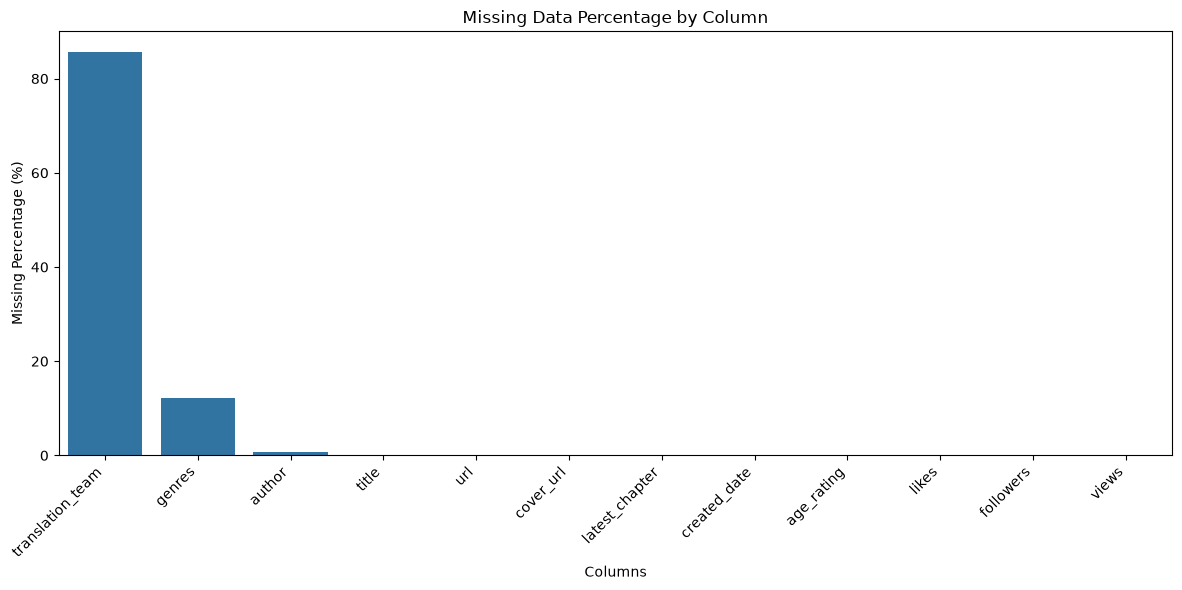

In [9]:
# Missing Value Columns
missing_data = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_data = missing_data.sort_values(
    by="Missing Percentage",
    ascending=False
)

print(missing_data)
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_data.index,
    y=missing_data["Missing Percentage"]
)

plt.title("Missing Data Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## Data Cleaning<br>
### What data quality issues exist in the dataset, such as missing values, duplicate records, and inconsistent data types?<br>
### How can these data quality issues be handled to prepare the dataset for analysis?<br>
#### Duplicate detection

In [10]:
# Checking duplicate (rows - url - titles)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Duplicate titles:", df["title"].duplicated().sum())

Duplicate rows: 0
Duplicate URLs: 0
Duplicate titles: 65


In [11]:
# Normalize title function: Normalize titles by converting all letters to lowercase and removing non-alphabetic and non-numbers characters. 
# Eg: "One piece 1" -> "onepiece1", "oNe - PIECE . 1" -> "onepiece1"
def normalize_title(title):
    title = title.lower()
    title = unicodedata.normalize("NFC", title)
    title = "".join(
        char for char in title
        if char.isalnum()
    )
    return title

df["normalized_title"] = df["title"].apply(normalize_title)
print(
    df[["title", "normalized_title"]].head(10)
)

                                         title  \
0                                   Batsu Hare   
1                       Reincarnation No Kaben   
2        Câu Chuyện Vươn Tới Đỉnh Cao Cuộc Đời   
3                                  Teto X Egen   
4                             Kỵ Sĩ Lang Thang   
5         Anata-Tachi Soredemo Sensei Desu Ka!   
6                               Võ Sĩ Bị Ma Ám   
7                    Cô Giáo Toki Muốn Thay Đồ   
8  Nàng Tiểu Thư Cộc Cằn Lại Lỡ Một Nhịp Rồi?!   
9                            Thiên Ma Quy Hoàn   

                   normalized_title  
0                         batsuhare  
1              reincarnationnokaben  
2    câuchuyệnvươntớiđỉnhcaocuộcđời  
3                         tetoxegen  
4                     kỵsĩlangthang  
5    anatatachisoredemosenseidesuka  
6                        võsĩbịmaám  
7              côgiáotokimuốnthayđồ  
8  nàngtiểuthưcộccằnlạilỡmộtnhịprồi  
9                    thiênmaquyhoàn  


In [12]:
# Checking duplicate (normalized title)
print("Duplicate titles:", df["normalized_title"].duplicated().sum())

Duplicate titles: 121


In [13]:
duplicate_titles = df[
    df.duplicated(
        subset=["normalized_title"],
        keep=False
    )
].sort_values("normalized_title")

columns_to_check = [
    "title",
    "normalized_title",
    "author",
    "genres",
    "created_date",
    "views",
    "likes",
    "followers",
    "latest_chapter"
]

print(duplicate_titles[columns_to_check].to_string(index=False))

                                                                                                              title                                                                                normalized_title                                    author                                                                                           genres created_date      views  likes followers latest_chapter
                                                                                      Ad Astra – Scipio To Hannibal                                                                         adastrascipiotohannibal                                  TruyenQQ                                              Action, Adventure, Drama, Psychological, Historical   09/04/2024    112,827     68       655     Chapter 34
                                                                                      Ad Astra - Scipio To Hannibal                                                                       

#### String cleaning

In [14]:
# Checking extra whitespace value function
def has_extra_whitespace(value):
    if isinstance(value, str):
        return value != value.strip() or "  " in value
    return False
# Cleaning whitespace function
def clean_whitespace(value):
    if isinstance(value, str):
        return " ".join(value.split())
    return value

In [15]:
string_columns = df.select_dtypes(
    include=["object", "str"]
).columns

# Checking extra whitespace value
for col in string_columns:
    count = df[col].apply(has_extra_whitespace).sum()
    print(f"{col}: {count}")

for col in string_columns:
    df[col] = df[col].apply(clean_whitespace)

print('-' * 20)
# Checking empty value
for col in string_columns:
    empty_count = (df[col] == "").sum()
    print(f"{col}: {empty_count}")

title: 26
url: 0
cover_url: 0
latest_chapter: 0
genres: 0
author: 1
created_date: 0
translation_team: 0
age_rating: 0
followers: 0
views: 0
normalized_title: 0
--------------------
title: 0
url: 0
cover_url: 0
latest_chapter: 0
genres: 0
author: 0
created_date: 0
translation_team: 0
age_rating: 0
followers: 0
views: 0
normalized_title: 0


2. Data Cleaning

* RQ2: What data quality issues exist in the dataset, such as missing values, duplicate records, and inconsistent data types?
* RQ3: How can these data quality issues be handled to prepare the dataset for analysis?

3. Genre Analysis

* RQ4: Which genres are the most common in the dataset?
* RQ5: Which genres have the highest average popularity?

4. Popularity Analysis

* RQ6: How are views, likes, and followers correlated?
* RQ7: Do comics with more chapters tend to be more popular?
* RQ8: Which comics have high views but relatively low likes?

5. Genre Relationships

* RQ9: Which genres frequently appear together?
* RQ10: How does the number of genres relate to comic popularity?

6. Temporal Analysis

* RQ11: How does a comic’s creation date relate to its popularity?

7. Recommendation System

* RQ12: How can we recommend comics based on genre similarity?